# JS11 - Praktikum 4: Klasifikasi Citra Wajah (LFW Faces)
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Pengenalan wajah publik figur menggunakan dataset LFW People, reduksi dimensi dengan PCA (150 komponen), dan SVC RBF yang dituning menggunakan `GridSearchCV`.


Menggunakan dataset LFW People (700 sampel citra wajah, 7 kelas figur publik)...
Tokoh: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Tony Blair']
Best params: {'svc__C': 5, 'svc__gamma': 0.005}

Classification Report:
                    precision    recall  f1-score   support

     Ariel Sharon       0.14      0.38      0.20        26
     Colin Powell       0.13      0.22      0.16        23
  Donald Rumsfeld       0.17      0.06      0.09        32
    George W Bush       0.00      0.00      0.00        23
Gerhard Schroeder       0.12      0.09      0.10        22
      Hugo Chavez       0.09      0.09      0.09        23
       Tony Blair       0.00      0.00      0.00        26

         accuracy                           0.12       175
        macro avg       0.09      0.12      0.09       175
     weighted avg       0.09      0.12      0.09       175



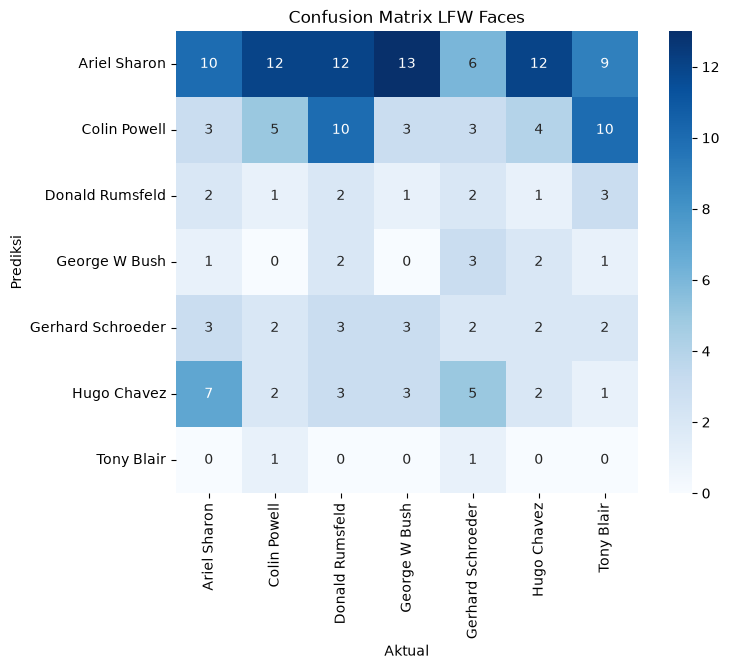

In [1]:
from sklearn.datasets import fetch_lfw_people
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

faces = fetch_lfw_people(min_faces_per_person=60)
print("Tokoh:", faces.target_names)

pca = PCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(pca, svc)

Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42, test_size=0.25)
param_grid = {'svc__C': [1, 5, 10], 'svc__gamma': [0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid, cv=3).fit(Xtrain, ytrain)

print("Best params:", grid.best_params_)
yfit = grid.best_estimator_.predict(Xtest)
print("\nClassification Report:\n", classification_report(ytest, yfit, target_names=faces.target_names))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(ytest, yfit).T, square=True, annot=True, fmt='d', cmap='Blues',
            xticklabels=faces.target_names, yticklabels=faces.target_names)
plt.title("Confusion Matrix LFW Faces")
plt.xlabel("Aktual")
plt.ylabel("Prediksi")
plt.show()
